# Read-sorting evaluation on PDX, PDXO & patient samples from Guillen et al. (2022)

## 0. Imports and paths

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import *
from helper.runtime_memory import *
from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path.cwd().parent / "data" / "guillen_2022"
rrbs_dir = data_dir / "rrbs"
rrems_dir = data_dir / "rrems"
results_dir = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" 
fig_dir_sort = fig_dir / "read_sorting"
fig_dir_sort.mkdir(exist_ok = True, parents=True)

fig_dir_time = fig_dir / "runtime_memory"
fig_dir_time.mkdir(exist_ok=True)
log_dir = Path.cwd() / "logs"

hue_order=["Xengsort", "ICRG", "bamcmp", "XenofilteR"]

## 1. Load evaluation TSVs

### RRBS

In [3]:
icrg_rrbs_mspi   = load_method(results_dir / "icrg_rrbs_mspi",   "icrg")
icrg_rrbs_mspi = split_guillen_names(icrg_rrbs_mspi, key="Sample")

xengsort_rrbs_mspi = load_method(results_dir / "xengsort_newindex_rrbs_mspi", "xengsort")
xengsort_rrbs_mspi = split_guillen_names(xengsort_rrbs_mspi, key="Sample")

sites_rrbs = xengsort_rrbs_mspi[xengsort_rrbs_mspi["Category"] == "sites"]
icrg_rrbs_mspi = pd.concat([icrg_rrbs_mspi, sites_rrbs.assign(Method="icrg")], ignore_index=True)

bamcmp_rrbs_mspi = load_method(results_dir / "bamcmp_rrbs_mspi", "bamcmp")
bamcmp_rrbs_mspi = split_guillen_names(bamcmp_rrbs_mspi, key="Sample")
bamcmp_rrbs_mspi = pd.concat([bamcmp_rrbs_mspi, sites_rrbs.assign(Method="bamcmp")], ignore_index=True)

xenofilter_rrbs_mspi = load_method(results_dir / "xenofilter_rrbs_mspi", "XenofilteR")
xenofilter_rrbs_mspi = split_guillen_names(xenofilter_rrbs_mspi, key="Sample")
xenofilter_rrbs_mspi = pd.concat([xenofilter_rrbs_mspi, sites_rrbs.assign(Method="XenofilteR")], ignore_index=True)

In [4]:
icrg_rrbs = split_guillen_names(load_method(results_dir / "icrg_rrbs", "icrg"))

xengsort_rrbs = split_guillen_names(load_method(results_dir / "xengsort_newindex_rrbs", "xengsort"))

bamcmp_rrbs = split_guillen_names(load_method(results_dir / "bamcmp_rrbs", "bamcmp"))

xenofilter_rrbs = split_guillen_names(load_method(results_dir / "xenofilter_rrbs", "XenofilteR"))

### RREMS

In [5]:

xengsort_rrems_mspi = load_method(results_dir / "xengsort_newindex_rrems_mspi", "xengsort")
xengsort_rrems_mspi["Sample"] = xengsort_rrems_mspi["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
xengsort_rrems_mspi["Reads"] = xengsort_rrems_mspi["Reads"] * 2
sites_rrems = xengsort_rrems_mspi[xengsort_rrems_mspi["Category"] == "sites"]

icrg_rrems_mspi   = load_method(results_dir / "icrg_rrems_mspi",   "icrg")
icrg_rrems_mspi["Sample"] = icrg_rrems_mspi["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
icrg_rrems_mspi = pd.concat([icrg_rrems_mspi, sites_rrems.assign(Method="icrg")], ignore_index=True)


bamcmp_rrems_mspi = load_method(results_dir / "bamcmp_rrems_mspi", "bamcmp")
bamcmp_rrems_mspi = split_guillen_names(bamcmp_rrems_mspi, key="Sample")
bamcmp_rrems_mspi = pd.concat([bamcmp_rrems_mspi, sites_rrems.assign(Method="bamcmp")], ignore_index=True)

xenofilter_rrems_mspi = load_method(results_dir / "xenofilter_rrems_mspi", "XenofilteR")
xenofilter_rrems_mspi = split_guillen_names(xenofilter_rrems_mspi, key="Sample")
xenofilter_rrems_mspi = pd.concat([xenofilter_rrems_mspi, sites_rrems.assign(Method="XenofilteR")], ignore_index=True)

In [6]:
icrg_rrems = load_method(results_dir / "icrg_rrems", "icrg")
icrg_rrems["Sample"] = icrg_rrems["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))

xengsort_rrems = load_method(results_dir / "xengsort_newindex_rrems", "xengsort")
xengsort_rrems["Sample"] = xengsort_rrems["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
xengsort_rrems["Reads"] = xengsort_rrems["Reads"] * 2

bamcmp_rrems = split_guillen_names(load_method(results_dir / "bamcmp_rrems", "bamcmp"))

xenofilter_rrems = split_guillen_names(load_method(results_dir / "xenofilter_rrems", "XenofilteR"))

In [ ]:
xengsort_rrems_mspi.groupby("Sample").agg(({"Rea"}))

,Category,Reads,Sample,Method
0,ambiguous,885060,HCI-003_PDX,xengsort
1,both,382428,HCI-003_PDX,xengsort
2,graft,17064316,HCI-003_PDX,xengsort
3,host,8463838,HCI-003_PDX,xengsort
4,neither,3256526,HCI-003_PDX,xengsort
...,...,...,...,...
115,both,2814566,HCI-039_Patient,xengsort
116,graft,108772670,HCI-039_Patient,xengsort
117,host,77164,HCI-039_Patient,xengsort
118,neither,964726,HCI-039_Patient,xengsort


## 2. Read sorting outcomes per method

### RRBS MspI

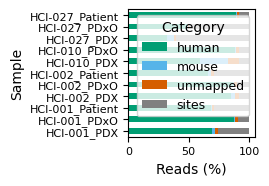

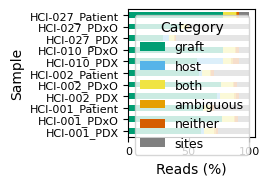

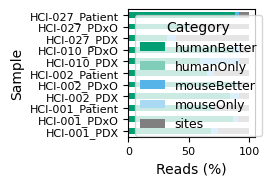

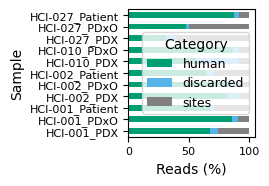

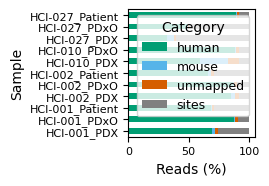

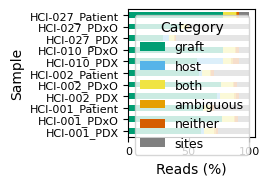

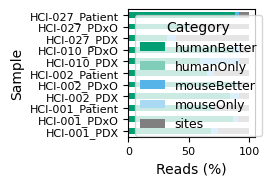

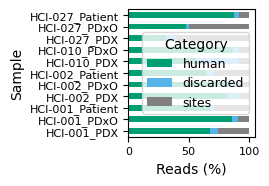

In [8]:
figsize=mm_to_inches((70, 50))

os.makedirs(fig_dir_sort / "rrbs_mspi", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrbs_mspi_pivot_pct = stacked_barplot(icrg_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi" , file_name = f"icrg_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrbs_mspi_pivot_pct = stacked_barplot(xengsort_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"xengsort_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrbs_mspi_pivot_pct = stacked_barplot(bamcmp_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"bamcmp_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    xenofilter_rrbs_mspi_pivot_pct = stacked_barplot(xenofilter_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"xenofilter_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )

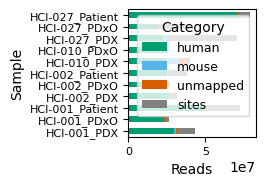

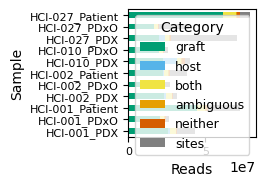

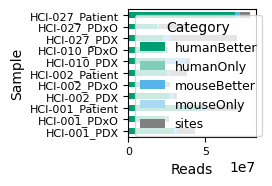

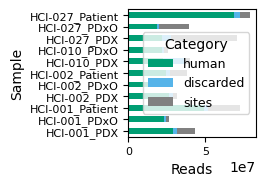

In [9]:
figsize=mm_to_inches((70, 50))

icrg_rrbs_mspi_pivot = stacked_barplot(icrg_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "icrg_rrbs_mspi_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrbs_mspi_pivot = stacked_barplot(xengsort_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "xengsort_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrbs_mspi_pivot = stacked_barplot(bamcmp_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "bamcmp_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
xenofilter_rrbs_mspi_pivot = stacked_barplot(xenofilter_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "xenofilter_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )



### RRBS non-MSPI

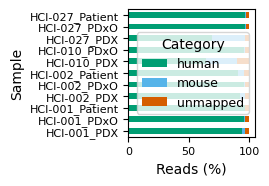

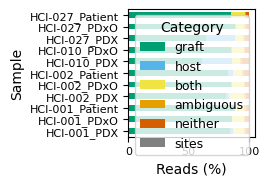

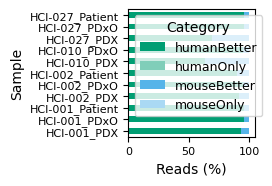

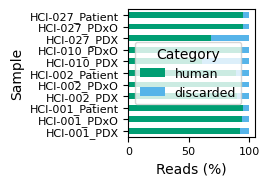

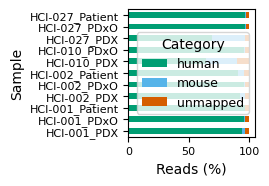

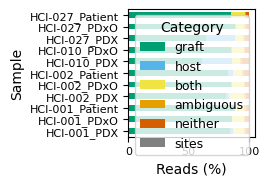

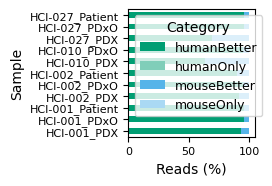

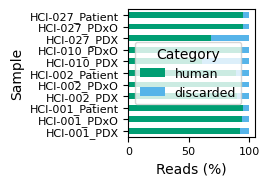

In [12]:
figsize=mm_to_inches((70, 50))
os.makedirs(fig_dir_sort / "rrbs", exist_ok  = True)
for suffix in ["pdf", "png"]:
    icrg_rrbs_pivot_pct = stacked_barplot(icrg_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"icrg_rrbs_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrbs_pivot_pct = stacked_barplot(xengsort_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"xengsort_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrbs_pivot_pct = stacked_barplot(bamcmp_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"bamcmp_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    xenofilter_rrbs_pivot_pct = stacked_barplot(xenofilter_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"xenofilter_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )

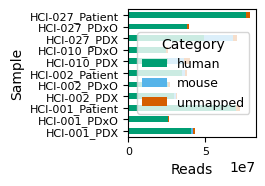

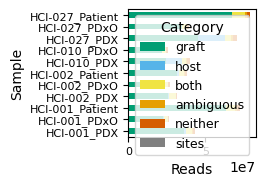

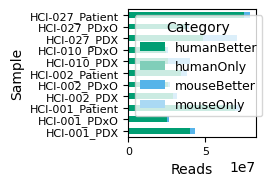

In [13]:
figsize=mm_to_inches((70, 50))
icrg_rrbs_pivot = stacked_barplot(icrg_rrbs, fig_dir = fig_dir_sort / "rrbs" , file_name = "icrg_rrbs_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrbs_pivot = stacked_barplot(xengsort_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = "xengsort_rrbs_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrbs_pivot = stacked_barplot(bamcmp_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = "bamcmp_rrbs_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )

In [21]:
xengsort_rrbs_mspi_pivot_pct

Category,graft,host,both,ambiguous,neither,sites
Sample,,,,,,
HCI-001_PDX,60.397175,2.149339,8.725626,0.924489,1.688611,26.114760
HCI-001_PDxO,77.754950,0.146940,9.414990,1.114019,2.462888,9.106212
HCI-001_Patient,61.508950,0.079110,6.975593,0.883668,1.884064,28.668614
HCI-002_PDX,73.420089,2.387979,12.053793,1.247569,2.161632,8.728938
HCI-002_PDxO,76.884398,0.134700,9.455277,1.150888,2.566405,9.808331
HCI-002_Patient,58.613735,2.163168,6.778232,1.036323,2.603147,28.805396
HCI-010_PDX,56.479657,22.261374,6.148313,1.649821,4.768321,8.692515
HCI-010_PDxO,78.456943,0.163962,9.573238,1.160527,2.527712,8.117618
HCI-027_PDX,28.619146,5.110817,3.983520,0.592815,1.107030,60.586671


In [ ]:
(xengsort_rrbs_mspi_pivot_pct - xengsort_rrbs_pivot_pct)

Category,graft,host,both,ambiguous,neither,sites
Sample,,,,,,
HCI-001_PDX,-23.503684,-0.405317,-1.030168,-0.352118,-0.823473,26.114760
HCI-001_PDxO,-7.873769,-0.151462,-0.336449,-0.141673,-0.602858,9.106212
HCI-001_Patient,-26.366018,-0.036804,-0.903609,-0.381474,-0.980709,28.668614
HCI-002_PDX,-7.178703,-0.496542,-0.430299,-0.132840,-0.490553,8.728938
HCI-002_PDxO,-8.565024,-0.119923,-0.350721,-0.152725,-0.619938,9.808331
HCI-002_Patient,-23.717380,-2.049323,-0.982370,-0.473295,-1.583027,28.805396
HCI-010_PDX,-4.524222,-2.897363,-0.382866,-0.226062,-0.662002,8.692515
HCI-010_PDxO,-6.754707,-0.325588,-0.294260,-0.130758,-0.612305,8.117618
HCI-027_PDX,-35.590805,-19.362438,-2.219979,-1.144291,-2.269159,60.586671


In [53]:
(xengsort_rrbs_mspi_pivot_pct - xengsort_rrbs_pivot_pct).mean(axis=0)

Category
graft       -17.878453
host         -2.375489
both         -0.820508
ambiguous    -0.356446
neither      -0.948323
sites        22.379219
dtype: float64

In [50]:
df = xengsort_rrbs_mspi_pivot_pct.rename_axis("Sample").reset_index()
df.columns.name = None
df["Type"] = df["Sample"].str.split("_").apply(lambda x: x[1])
df.groupby("Type")["sites"].agg(["mean", "median", "std", "min", "max"])

,mean,median,std,min,max
Type,,,,,
PDX,26.030721,17.421849,24.454624,8.692515,60.586671
PDxO,19.141638,9.457272,20.273701,8.117618,49.534392
Patient,21.827324,28.668614,11.968114,8.007962,28.805396


In [62]:
df["sites"].median()

np.float64(8.909433108859753)

### RREMS

#### No MspI filtering


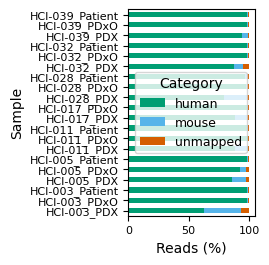

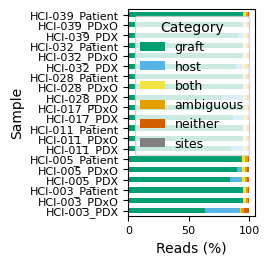

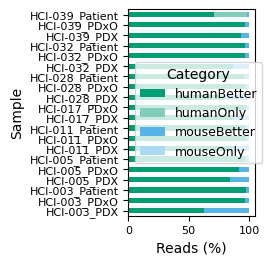

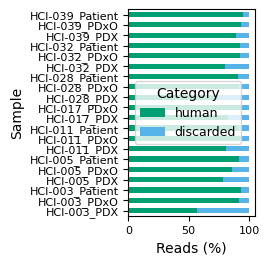

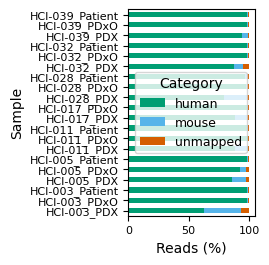

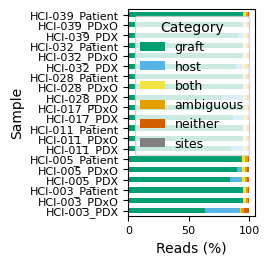

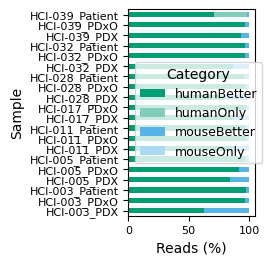

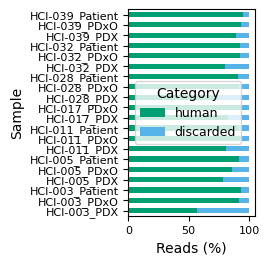

In [55]:
figsize=mm_to_inches((70, 70))
os.makedirs(fig_dir_sort / "rrems", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrems_pivot_pct = stacked_barplot(icrg_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"icrg_rrems_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrems_pivot_pct = stacked_barplot(xengsort_rrems, fig_dir = fig_dir_sort / "rrems" , file_name = f"xengsort_rrems_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrems_pivot_pct = stacked_barplot(bamcmp_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"bamcmp_rrems_stacked_barplot_pct.{suffix}", percent = True, save=True, figsize=figsize, colors= category_colors)
    xenofilter_rrems_pivot_pct = stacked_barplot(xenofilter_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"xenofilter_rrems_stacked_barplot_pct.{suffix}", percent=True, save=True, figsize=figsize, colors= category_colors)

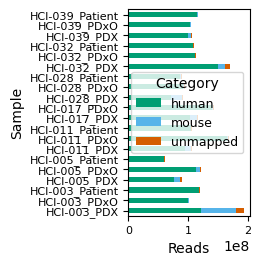

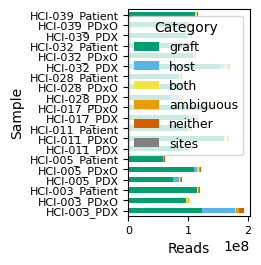

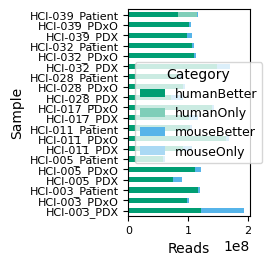

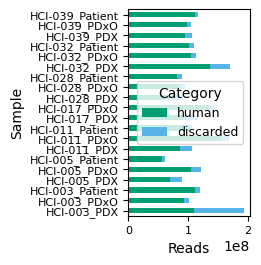

In [29]:
figsize=mm_to_inches((70, 70))
icrg_rrems_pivot = stacked_barplot(icrg_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "icrg_rrems_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrems_pivot = stacked_barplot(xengsort_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "xengsort_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrems_pivot = stacked_barplot(bamcmp_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "bamcmp_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
xenofilter_rrems_pivot = stacked_barplot(xenofilter_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "xenofilter_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )

#### Mspi Prefiltering

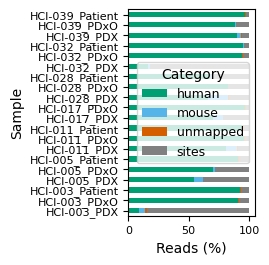

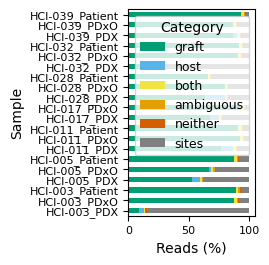

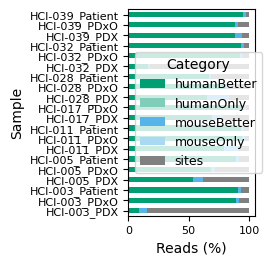

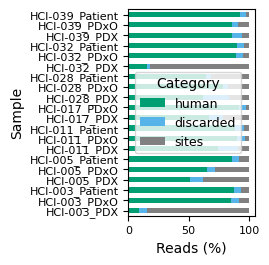

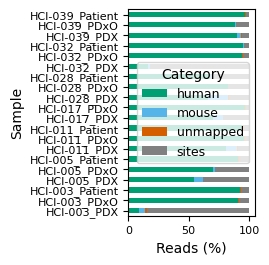

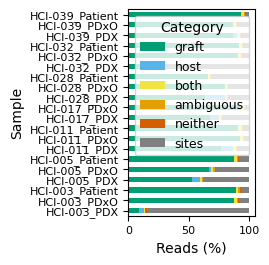

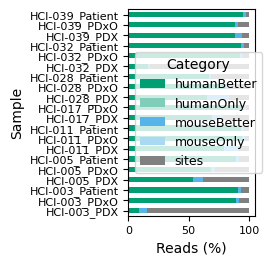

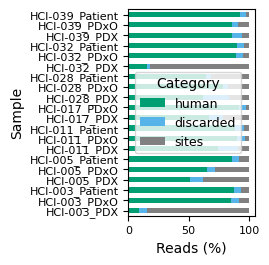

In [23]:
figsize=mm_to_inches((70, 70))
os.makedirs(fig_dir_sort / "rrems_mspi", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrems_mspi_pivot_pct = stacked_barplot(icrg_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"icrg_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrems_mspi_pivot_pct = stacked_barplot(xengsort_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"xengsort_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrems_mspi_pivot_pct = stacked_barplot(bamcmp_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"bamcmp_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xenofilter_rrems_mspi_pivot_pct = stacked_barplot(xenofilter_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"xenofilter_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)

In [70]:

xengsort_rrbs_mspi_pivot_pct[["sites"]].sort_values(by="sites", ascending=False)


Category,sites
Sample,
HCI-027_PDX,60.586671
HCI-027_PDxO,49.534392
HCI-002_Patient,28.805396
HCI-001_Patient,28.668614
HCI-001_PDX,26.114760
HCI-002_PDxO,9.808331
HCI-001_PDxO,9.106212
HCI-002_PDX,8.728938
HCI-010_PDX,8.692515


In [69]:
xengsort_rrems_mspi_pivot_pct[["sites"]].sort_values(by="sites", ascending=False)

Category,sites
Sample,
HCI-003_PDX,84.428544
HCI-032_PDX,82.310393
HCI-005_PDX,37.933526
HCI-028_Patient,31.425767
HCI-005_PDxO,27.943690
HCI-017_PDX,21.429411
HCI-028_PDxO,17.032729
HCI-028_PDX,16.805396
HCI-011_PDX,9.245658


In [59]:
df = xengsort_rrems_mspi_pivot_pct.rename_axis("Sample").reset_index()
df.columns.name = None
df["Type"] = df["Sample"].str.split("_").apply(lambda x: x[1])
df.groupby("Type")["sites"].agg(["mean", "median", "std", "min", "max"])

,mean,median,std,min,max
Type,,,,,
PDX,36.883189,21.429411,33.374196,6.029393,84.428544
PDxO,10.559008,8.459378,9.051883,2.833374,27.943690
Patient,9.699855,5.721419,10.861019,2.626036,31.425767


In [60]:
df["sites"].median()

np.float64(8.909433108859753)

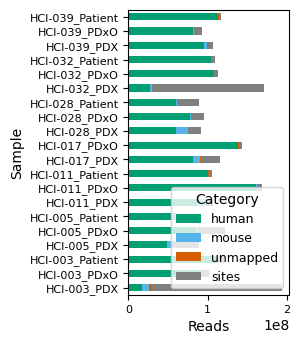

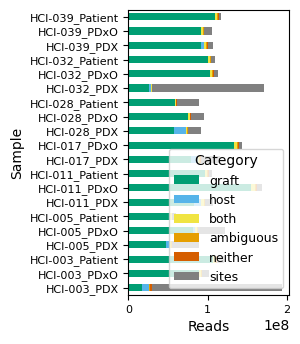

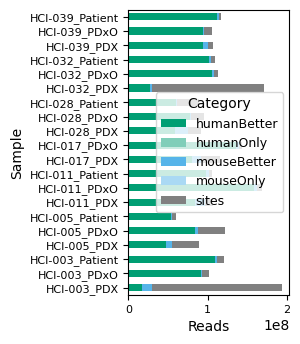

In [31]:
icrg_rrems_mspi_pivot = stacked_barplot(icrg_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "icrg_rrems_mspi_stacked_barplot.pdf", percent=False, save = True, figsize=mm_to_inches((80, 90)), colors = category_colors)
xengsort_rrems_mspi_pivot = stacked_barplot(xengsort_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "xengsort_rrems_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=mm_to_inches((80, 90)), colors = category_colors, )
bamcmp_rrems_mspi_pivot = stacked_barplot(bamcmp_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "bamcmp_rrems_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=mm_to_inches((80, 90)), colors = category_colors, )

In [56]:
xengsort_rrems_mspi_pivot_pct - xengsort_rrems_pivot_pct

Category,graft,host,both,ambiguous,neither,sites
Sample,,,,,,
HCI-003_PDX,-54.560992,-24.377736,-0.806477,-2.601734,-2.081606,84.428544
HCI-003_PDxO,-7.281899,-0.092499,-0.108264,-0.565255,-0.411461,8.459378
HCI-003_Patient,-6.064019,-0.031864,-0.091527,-0.437369,-0.378152,7.002931
HCI-005_PDX,-31.675905,-3.480159,-0.573682,-1.209579,-0.994202,37.933526
HCI-005_PDxO,-23.424051,-2.316782,-0.401131,-0.986357,-0.815370,27.943690
HCI-005_Patient,-6.980851,-0.055284,-0.116514,-0.886291,-0.593775,8.632714
HCI-011_PDX,-7.605953,-0.768861,-0.119701,-0.399574,-0.351569,9.245658
HCI-011_PDxO,-2.880894,-0.019422,-0.048939,-0.206868,-0.247128,3.403251
HCI-011_Patient,-3.770408,-0.020415,-0.062228,-0.300644,-0.286211,4.439907


In [58]:
(xengsort_rrems_mspi_pivot_pct - xengsort_rrems_pivot_pct).mean(axis=0)

Category
graft       -15.952584
host         -1.958940
both         -0.229593
ambiguous    -0.732771
neither      -0.640836
sites        19.514725
dtype: float64

## 3. Xengsort output overview over PDX samples

In [9]:
xengsort_rrems_pdx = xengsort_rrems[xengsort_rrems["Sample"].str.split("_").apply(lambda x: x[1] == "PDX")]
xengsort_rrbs_pdx = xengsort_rrbs[xengsort_rrbs["Sample"].str.split("_").apply(lambda x: x[1] == "PDX")]

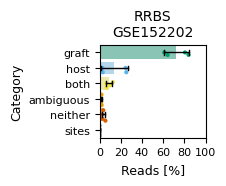

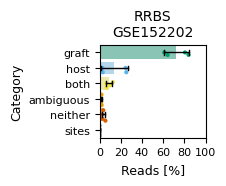

In [10]:
df_xengsort_rrbs_pdx = plot_xengsort_summary(xengsort_rrbs_pdx,percent=True, figsize=mm_to_inches((60, 50)), xticks = [0, 20, 40, 60, 80, 100], size=3, legend=False, save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrbs_pdx_summary.pdf", title="RRBS\nGSE152202")
plot_xengsort_summary(xengsort_rrbs_pdx,percent=True, figsize=mm_to_inches((60, 50)), xticks = [0, 20, 40, 60, 80, 100], size=3, legend=False, save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrbs_pdx_summary.png", title="RRBS\nGSE152202");

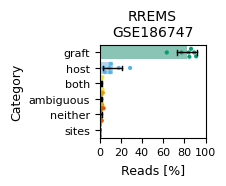

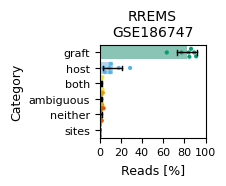

In [11]:
df_xengsort_rrems_pdx = plot_xengsort_summary(xengsort_rrems_pdx,percent=True, figsize=mm_to_inches((60, 50)), legend=False, xticks = [0, 20, 40, 60, 80, 100], save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrems_pdx_summary.pdf", title="RREMS\nGSE186747", size = 3)
plot_xengsort_summary(xengsort_rrems_pdx,percent=True, figsize=mm_to_inches((60, 50)), legend=False, xticks = [0, 20, 40, 60, 80, 100], save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrems_pdx_summary.png", title="RREMS\nGSE186747", size = 3);

## 4. Runtime and memory

### RRBS


####  Sorting runtime & memory

In [12]:
sorting_rrbs_xengsort = parse_lsf_logs(log_dir / "logs_newindex", method="Xengsort", pattern="xengsort_rrbs*.out")
# Strip RRBS_ prefix and trailing _0 to match xengsort evaluation sample names
sorting_rrbs_xengsort["sample"] = sorting_rrbs_xengsort["sample"].str.replace(r"^RRBS_", "", regex=True)
sorting_rrbs_xengsort.drop("replicate", axis =1, inplace=True)

sorting_rrbs_xengsort1, sorting_rrbs_xengsort_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrbs_xengsort)]

In [35]:
sorting_rrbs_xengsort1

,sample,realtime_s,peak_rss_mb,method
0,HCI-001_PDX,216.0,40897.0,Xengsort
1,HCI-001_PDxO,186.0,40890.0,Xengsort
2,HCI-001_Patient,261.0,40887.0,Xengsort
3,HCI-002_PDX,323.0,40831.0,Xengsort
4,HCI-002_PDxO,317.0,40836.0,Xengsort
5,HCI-002_Patient,327.0,40848.0,Xengsort
6,HCI-010_PDX,342.0,41235.0,Xengsort
7,HCI-010_PDxO,319.0,40826.0,Xengsort
8,HCI-027_PDX,398.0,40860.0,Xengsort
9,HCI-027_PDxO,338.0,40846.0,Xengsort


In [18]:
sorting_bamcmp = parse_lsf_logs(log_dir, method="bamcmp", pattern="guillen_bamcmp*.out")
sorting_rrbs_bamcmp = sorting_bamcmp[sorting_bamcmp["sample"].str.contains("assay: rrbs")]
sorting_rrbs_bamcmp.drop("replicate", axis =1, inplace=True)

sorting_rrbs_bamcmp1, sorting_rrbs_bamcmp_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrbs_bamcmp)]        

In [37]:
sorting_rrbs_xenofilter = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrbs_*.out")
sorting_rrbs_xenofilter.drop("replicate", axis =1, inplace=True)
sorting_rrbs_xenofilter1 = split_guillen_names(sorting_rrbs_xenofilter, key="sample")
sorting_rrbs_xenofilter_mspi = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrbs_mspi*.out")
sorting_rrbs_xenofilter_mspi.drop("replicate", axis =1, inplace=True)


In [38]:
sorting_rrbs = pd.concat([sorting_rrbs_xengsort1, sorting_rrbs_bamcmp1, sorting_rrbs_xenofilter], ignore_index=True)
sorting_rrbs = transform_runmem(sorting_rrbs)


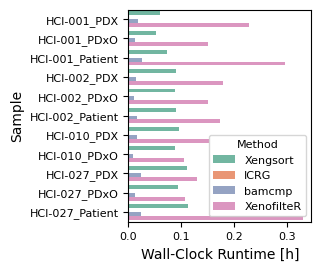

In [39]:
ax, pos = barplot_runmem(sorting_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 70)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_xengsort_rrbs_realtime.pdf")


#### Alignments Runtime and Memory

In [40]:
pipelines_rrbs = {
    "ICRG":       ["pipeline_icrg"],
    "Xengsort":   ["pipeline_xengsort_newindex"],
    "bamcmp":     ["pipeline_mouse", "pipeline_human"],
    "XenofilteR": ["pipeline_mouse", "pipeline_human"],
}


In [45]:
alignments_rrbs = process_nfcore_traces(rrbs_dir , pipeline_method_map=pipelines_rrbs)
alignments_rrbs = transform_runmem(alignments_rrbs)
alignments_rrbs = split_guillen_names(alignments_rrbs, key="sample")
alignments_rrbs

,sample,realtime_s,peak_rss_mb,method,stage,realtime_h,peak_rss_gb
0,HCI-001_PDX,813.0,93100.0,ICRG,alignment,0.225833,93.1
1,HCI-001_PDxO,555.0,93800.0,ICRG,alignment,0.154167,93.8
2,HCI-001_Patient,1260.0,92500.0,ICRG,alignment,0.350000,92.5
3,HCI-002_PDX,644.0,94800.0,ICRG,alignment,0.178889,94.8
4,HCI-002_PDxO,528.0,94300.0,ICRG,alignment,0.146667,94.3
5,HCI-002_Patient,681.0,90700.0,ICRG,alignment,0.189167,90.7
6,HCI-010_PDX,833.0,95400.0,ICRG,alignment,0.231389,95.4
7,HCI-010_PDxO,527.0,94400.0,ICRG,alignment,0.146389,94.4
8,HCI-027_PDX,1136.0,89600.0,ICRG,alignment,0.315556,89.6
9,HCI-027_PDxO,669.0,90400.0,ICRG,alignment,0.185833,90.4


#### No MspI Filtering

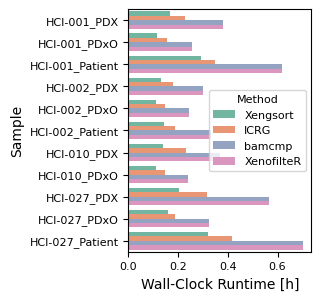

In [43]:
ax, pos = barplot_runmem(alignments_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 80)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_alignment_rrbs_realtime.pdf")

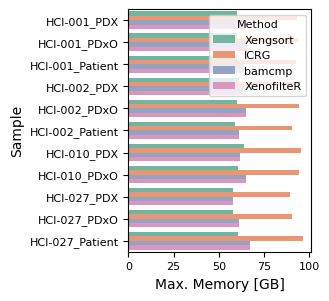

In [46]:
ax, pos = barplot_runmem(alignments_rrbs, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 80)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_alignment_rrbs_maxmem.pdf")

### Sorting + Alignment: Runtime and Memory

In [47]:
concat_rrbs = pd.concat([alignments_rrbs, sorting_rrbs], ignore_index = True)


In [48]:
final_rrbs = (
    concat_rrbs
    .groupby(["sample", "method"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_rrbs["realtime_h"]  = final_rrbs["realtime_s"] / 3600
final_rrbs["peak_rss_gb"] = final_rrbs["peak_rss_mb"] / 1000

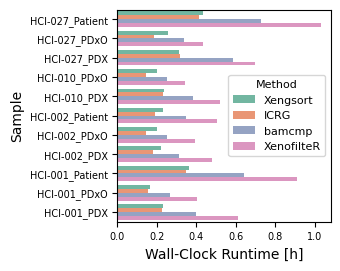

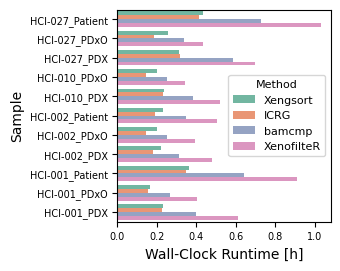

In [49]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=7, ytick_fs=7, reverse_order = True,
                figsize=mm_to_inches((70, 70)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrbs_realtime.{suffix}")


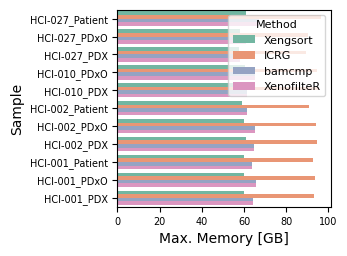

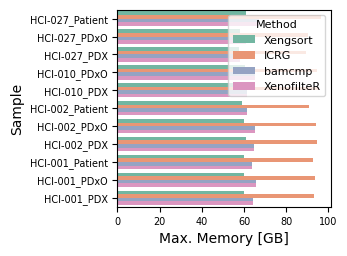

In [50]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrbs, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, ytick_fs=7, xtick_fs = 7, reverse_order =True,
                figsize=mm_to_inches((70, 65)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrbs_maxmemory.{suffix}")


### RREMS

In [14]:
sorting_rrems_xengsort = parse_lsf_logs(log_dir / "logs_newindex", method="Xengsort", pattern="xengsort_rrems*.out")

sorting_rrems_xengsort["sample"] = sorting_rrems_xengsort["sample"].str.replace(r"^RRBS_", "", regex=True)
sorting_rrems_xengsort.drop("replicate", axis =1, inplace=True)
sorting_rrems_xengsort1, sorting_rrems_xengsort_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrems_xengsort)]


In [19]:

sorting_rrems_bamcmp = sorting_bamcmp[sorting_bamcmp["sample"].str.contains("assay: rrems")]
sorting_rrems_bamcmp1, sorting_rrems_bamcmp_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrems_bamcmp)]  

In [20]:
sorting_rrems_xenofilter = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrems_*.out")
sorting_rrems_xenofilter.drop("replicate", axis =1, inplace=True)
sorting_rrems_xenofilter1 = split_guillen_names(sorting_rrems_xenofilter, key="sample")
sorting_rrems_xenofilter_mspi = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrems_mspi*.out")
sorting_rrems_xenofilter_mspi.drop("replicate", axis =1, inplace=True)


In [21]:
sorting_rrems = pd.concat([sorting_rrems_xengsort1, sorting_rrems_bamcmp1, sorting_rrems_xenofilter1], ignore_index=True)
sorting_rrems = transform_runmem(sorting_rrems)

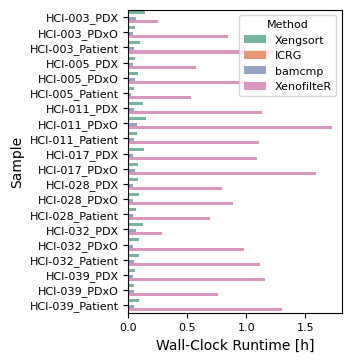

In [22]:
ax, pos = barplot_runmem(sorting_rrems, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_xengsort_rrems_realtime.pdf")


#### Alignment

In [23]:
pipelines_rrems = {
    "ICRG":       ["pipeline_icrg"],
    "Xengsort":   ["pipeline_xengsort_newindex"],
    "bamcmp":     ["pipeline_mouse", "pipeline_human"],
    "XenofilteR": ["pipeline_mouse", "pipeline_human"],
}


In [25]:
alignments_rrems = process_nfcore_traces(rrems_dir , pipeline_method_map=pipelines_rrems)
alignments_rrems = transform_runmem(alignments_rrems)
alignments_rrems = split_guillen_names(alignments_rrems, key="sample")


#### Sorting + Alignment

In [26]:
concat_rrems = pd.concat([alignments_rrems, sorting_rrems], ignore_index = True)

In [27]:
final_rrems = (
    concat_rrems
    .groupby(["sample", "method"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_rrems["realtime_h"]  = final_rrems["realtime_s"] / 3600
final_rrems["peak_rss_gb"] = final_rrems["peak_rss_mb"] / 1000


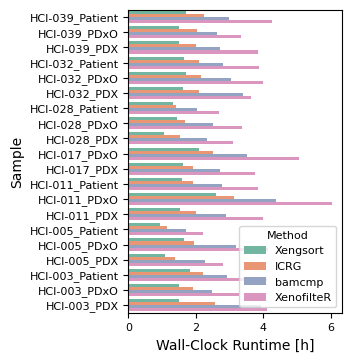

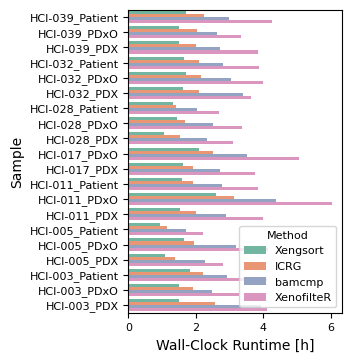

In [28]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrems, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=8, ytick_fs=8, reverse_order = True,
                figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrems_realtime.{suffix}")


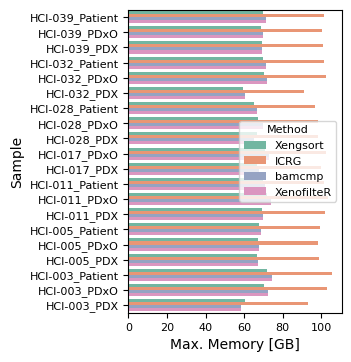

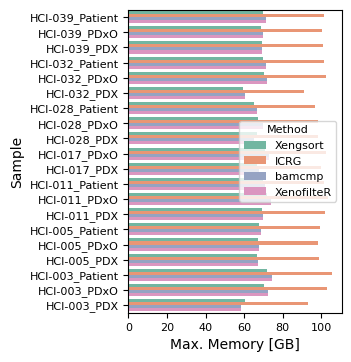

In [29]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrems, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=8, ytick_fs=8, reverse_order = True,
                figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrems_maxmem.{suffix}")
